# Recherche sémantique par plongements de textes
### *Semantic Search using Text Embeddings*

**Projet NLP — Master** · Réalisé par **Eya Dhrif** et **Almouthana Taha Khalfallah**

| | |
|---|---|
| **Tâche** | Recherche d'information : pour une requête, classer les documents d'un corpus du plus au moins pertinent. |
| **Données** | BEIR **SciFact** — 5 183 résumés scientifiques, 1 109 affirmations, jugements de pertinence humains. |
| **Baselines** | TF-IDF et BM25 (paramètres choisis par validation croisée). |
| **Modèles avancés** | Encodeurs de phrases (Sentence-BERT, E5, BGE) et recherche hybride BM25 + plongements. |
| **Métriques** | nDCG@10 (principale), MRR@10, Précision@10, Rappel@10, Rappel@100. |

**Plan** : 1. Introduction · 2. État de l'art · 3. Données · 4. Prétraitement · 5. Méthodologie · 6. Baselines · 7. Modèles avancés · 8. Résultats · 9. Analyse des erreurs · 10. Analyse critique et perspectives · 11. Conclusion · 12. Références

## 1. Introduction et problématique

Les moteurs de recherche classiques comparent les **mots** de la requête à ceux des documents. Or, un même concept s'exprime souvent avec des mots différents : c'est le **décalage de vocabulaire**. Par exemple, l'affirmation *« le tabac augmente le risque de cancer »* peut être prouvée par un résumé qui parle de *« fumée de cigarette »* et de *« carcinome »*.

La **recherche sémantique** résout ce problème en transformant requêtes et documents en **vecteurs (plongements)** produits par un réseau de neurones. Deux textes de même sens ont des vecteurs proches, même s'ils ne partagent aucun mot. Chercher revient alors à trouver les vecteurs les plus proches.

**Problématique** : *les plongements de textes permettent-ils de mieux retrouver les preuves scientifiques d'une affirmation que les méthodes lexicales classiques ?*

**Questions étudiées**
1. Les modèles de plongements dépassent-ils une baseline BM25 bien réglée ?
2. Combiner recherche lexicale et sémantique (hybride) apporte-t-il un gain supplémentaire ?
3. Dans quels cas chaque approche réussit ou échoue ?

## 2. État de l'art

| Période | Approche | Idée principale |
|---|---|---|
| 1970–1990 | **TF-IDF**, modèle vectoriel (Salton) | Un mot compte s'il est fréquent dans le document et rare dans le corpus. |
| 1994 | **BM25** (Robertson) | TF-IDF amélioré : saturation de la fréquence et normalisation par la longueur. Toujours une référence très solide. |
| 2013–2014 | **Word2Vec, GloVe** | Vecteurs de mots appris ; un texte = moyenne de ses mots. |
| 2019 | **BERT, Sentence-BERT** (Reimers & Gurevych) | Un Transformer encode toute la phrase ; entraîné sur des paires de phrases similaires. |
| 2020 | **DPR** (Karpukhin et al.) | Recherche dense : un encodeur pour la requête, un pour le document. |
| 2021 | **BEIR** (Thakur et al.) | Banc d'essai : BM25 reste difficile à battre hors du domaine d'entraînement. |
| 2022–2023 | **E5, BGE** | Pré-entraînement contrastif sur des centaines de millions de paires de textes : l'état de l'art actuel des encodeurs compacts. |

**Positionnement** : nous comparons ces générations de méthodes sur un même jeu de données scientifiques, avec un protocole d'évaluation rigoureux.

## 3. Données

**Source** : BEIR SciFact (Wadden et al., 2020) — https://github.com/beir-cellar/beir · https://huggingface.co/datasets/BeIR/scifact
Téléchargement direct : https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/scifact.zip

- **Corpus** : résumés d'articles biomédicaux (titre + texte).
- **Requêtes** : affirmations scientifiques rédigées par des experts.
- **Jugements (qrels)** : pour chaque requête, les documents qui la confirment ou la réfutent.
- Découpage officiel : **train** (809 requêtes, utilisé pour régler les paramètres) et **test** (300 requêtes, utilisé une seule fois pour l'évaluation finale).

In [1]:
import json, time, random, re, zipfile, urllib.request, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Appareil de calcul :", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Appareil de calcul : cuda NVIDIA GeForce RTX 2050


In [2]:
DATA = Path("data/scifact")
if not DATA.exists():  # téléchargement automatique au premier lancement
    Path("data").mkdir(exist_ok=True)
    urllib.request.urlretrieve("https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/scifact.zip", "data/scifact.zip")
    zipfile.ZipFile("data/scifact.zip").extractall("data")

def read_jsonl(p):
    with open(p, encoding="utf-8") as f:
        return [json.loads(l) for l in f]

corpus = pd.DataFrame(read_jsonl(DATA / "corpus.jsonl")).set_index("_id")
queries = pd.DataFrame(read_jsonl(DATA / "queries.jsonl")).set_index("_id")["text"]

def read_qrels(split):
    df = pd.read_csv(DATA / "qrels" / f"{split}.tsv", sep="\t", dtype=str)
    qrels = {}
    for q, d, s in df.itertuples(index=False):
        qrels.setdefault(q, {})[d] = int(s)
    return qrels

qrels = {s: read_qrels(s) for s in ["train", "test"]}
doc_ids = corpus.index.tolist()
doc_texts = (corpus["title"].fillna("") + ". " + corpus["text"].fillna("")).tolist()
q_train = queries.loc[list(qrels["train"])]
q_test = queries.loc[list(qrels["test"])]

print(f"Documents : {len(corpus)} | requêtes train : {len(q_train)} | requêtes test : {len(q_test)}")
corpus.head(3)

Documents : 5183 | requêtes train : 809 | requêtes test : 300


,title,text
_id,,
4983,Microstructural development of human newborn c...,Alterations of the architecture of cerebral wh...
5836,Induction of myelodysplasia by myeloid-derived...,Myelodysplastic syndromes (MDS) are age-depend...
7912,"BC1 RNA, the transcript from a master gene for...",ID elements are short interspersed elements (S...


### 3.1 Exploration du corpus

,Longueur moyenne (mots),Médiane,Max
Documents,214.6,204.0,1541
Requêtes,12.4,12.0,39


Documents pertinents par requête (test) : {1: 277, 2: 14, 3: 4, 4: 3, 5: 2}


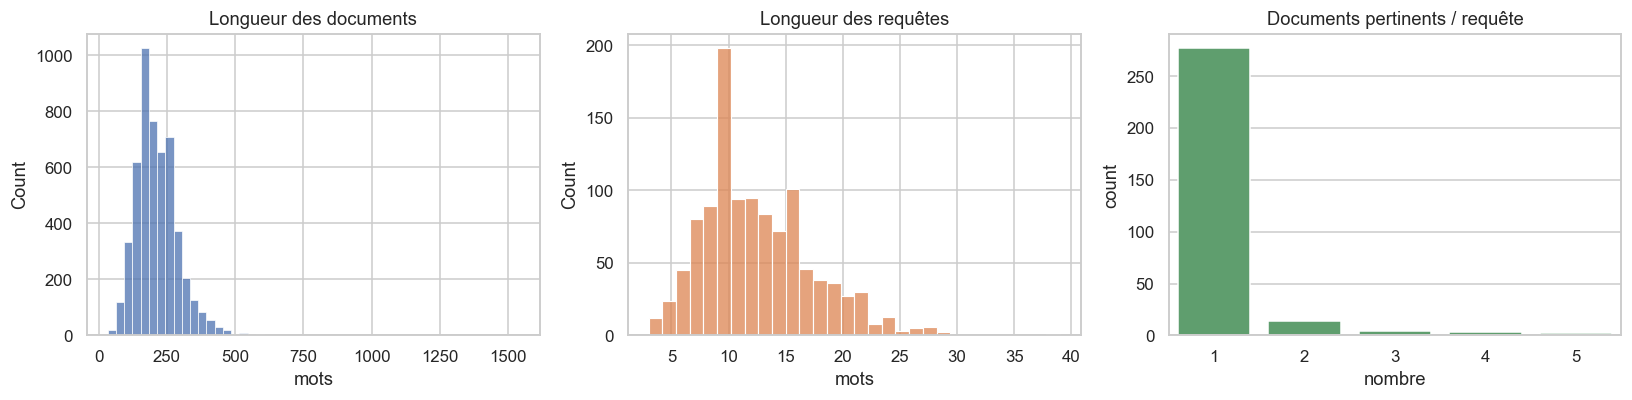

In [3]:
doc_len = pd.Series([len(t.split()) for t in doc_texts])
q_len = queries.str.split().str.len()
rel_per_q = pd.Series([len(v) for v in qrels["test"].values()])

stats = pd.DataFrame({
    "Longueur moyenne (mots)": [doc_len.mean(), q_len.mean()],
    "Médiane": [doc_len.median(), q_len.median()],
    "Max": [doc_len.max(), q_len.max()],
}, index=["Documents", "Requêtes"]).round(1)
display(stats)
print("Documents pertinents par requête (test) :", rel_per_q.value_counts().sort_index().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(doc_len, bins=50, ax=ax[0], color="C0"); ax[0].set(title="Longueur des documents", xlabel="mots")
sns.histplot(q_len, bins=30, ax=ax[1], color="C1"); ax[1].set(title="Longueur des requêtes", xlabel="mots")
sns.countplot(x=rel_per_q, ax=ax[2], color="C2"); ax[2].set(title="Documents pertinents / requête", xlabel="nombre")
plt.tight_layout(); plt.show()

**Observations**
- Les requêtes sont **très courtes** (~12 mots) face à des documents longs (~200 mots) : la requête contient peu d'indices.
- La plupart des requêtes n'ont **qu'un seul document pertinent** parmi 5 183 : la tâche est exigeante, il faut le placer tout en haut du classement.

### 3.2 Mesure du décalage de vocabulaire
Pour chaque paire (requête, document pertinent), nous calculons la part des mots de la requête qui apparaissent aussi dans le document.

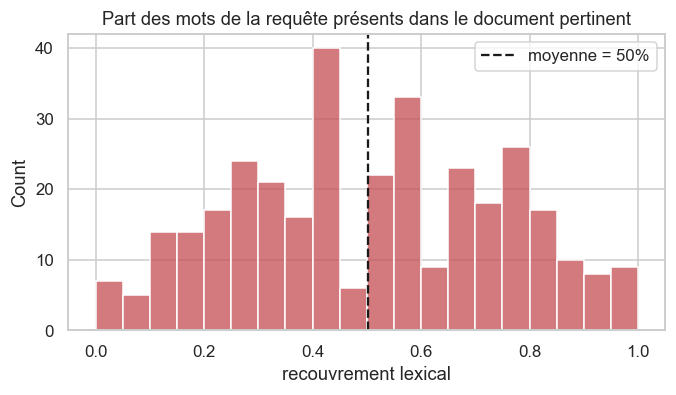

48% des paires partagent moins de la moitié de leurs mots.


In [4]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
tok = lambda t: [w for w in re.findall(r"[a-z0-9]+", t.lower()) if w not in ENGLISH_STOP_WORDS]
id2text = dict(zip(doc_ids, doc_texts))

overlap = []
for q, rels in qrels["test"].items():
    qw = set(tok(queries[q]))
    for d in rels:
        overlap.append(len(qw & set(tok(id2text[d]))) / max(len(qw), 1))
overlap = np.array(overlap)

plt.figure(figsize=(7, 3.5))
sns.histplot(overlap, bins=20, color="C3")
plt.axvline(overlap.mean(), color="k", ls="--", label=f"moyenne = {overlap.mean():.0%}")
plt.title("Part des mots de la requête présents dans le document pertinent")
plt.xlabel("recouvrement lexical"); plt.legend(); plt.show()
print(f"{(overlap < 0.5).mean():.0%} des paires partagent moins de la moitié de leurs mots.")

**Conclusion de l'exploration** : en moyenne, une part importante des mots de la requête **n'apparaît pas** dans le document pertinent. C'est exactement le cas où une méthode basée uniquement sur les mots est pénalisée, ce qui motive l'utilisation des plongements.

## 4. Prétraitement

Le prétraitement dépend du type de modèle :

| Étape | Méthodes lexicales (TF-IDF, BM25) | Plongements (Transformers) |
|---|---|---|
| Minuscules | ✅ « Cancer » = « cancer » | ❌ géré par le tokenizer du modèle |
| Suppression des mots vides | ✅ « the », « of » n'apportent pas de sens | ❌ ils portent la structure de la phrase |
| Racinisation (Porter) | ✅ « infections » → « infect » regroupe les variantes | ❌ le modèle connaît déjà les variantes |
| Texte d'entrée | titre + résumé | titre + résumé, texte brut |

**Justification** : les modèles lexicaux comptent des mots exacts, il faut donc normaliser. Les Transformers ont été pré-entraînés sur du texte naturel : le modifier leur ferait perdre de l'information.

In [5]:
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()
_cache = {}
def stem(w):
    if w not in _cache:
        _cache[w] = stemmer.stem(w)
    return _cache[w]

def preprocess(text):
    return [stem(w) for w in tok(text)]

exemple = queries[q_test.index[0]]
print("Texte brut  :", exemple)
print("Prétraité   :", preprocess(exemple))

t0 = time.time()
corpus_tokens = [preprocess(t) for t in doc_texts]
print(f"Corpus prétraité en {time.time()-t0:.1f} s — vocabulaire : {len(set(w for d in corpus_tokens for w in d)):,} racines")

Texte brut  : 0-dimensional biomaterials show inductive properties.
Prétraité   : ['0', 'dimension', 'biomateri', 'induct', 'properti']


Corpus prétraité en 0.8 s — vocabulaire : 25,963 racines


## 5. Méthodologie et protocole expérimental

**Pipeline** : chaque méthode attribue un score à chaque document pour chaque requête ; les documents sont ensuite triés par score décroissant.

```
requête ─► [ TF-IDF | BM25 | encodeur dense | hybride ] ─► scores des 5 183 documents ─► classement ─► métriques
```

**Métriques** (adaptées au classement, pas à la classification) :
- **nDCG@10** *(métrique principale, standard BEIR)* : qualité du top 10, récompense les documents pertinents placés tôt.
- **MRR@10** : 1 / rang du premier document pertinent.
- **Précision@10** : part de documents pertinents dans le top 10.
- **Rappel@10 / Rappel@100** : part des documents pertinents retrouvés dans le top 10 / top 100.

**Protocole**
- Les paramètres (BM25 *k1*, *b* ; poids α de l'hybride) sont choisis par **validation croisée à 5 plis sur les requêtes train**.
- Les requêtes **test** ne servent qu'à l'évaluation finale : aucune décision n'est prise en les regardant.
- Significativité : **intervalle de confiance bootstrap à 95 %** et **test de permutation apparié** par rapport à BM25.

In [6]:
def to_run(scores, qids, k=100):
    # matrice de scores (requêtes × documents) -> {qid: [doc_id classés]}
    top = np.argpartition(-scores, k, axis=1)[:, :k]
    run = {}
    for i, q in enumerate(qids):
        idx = top[i][np.argsort(-scores[i, top[i]])]
        run[q] = [doc_ids[j] for j in idx]
    return run

def per_query(run, qrels_split):
    rows = {}
    for q, ranked in run.items():
        rel = qrels_split[q]
        gains = [rel.get(d, 0) for d in ranked[:10]]
        dcg = sum(g / np.log2(i + 2) for i, g in enumerate(gains))
        idcg = sum(g / np.log2(i + 2) for i, g in enumerate(sorted(rel.values(), reverse=True)[:10]))
        first = next((i for i, d in enumerate(ranked[:10]) if d in rel), None)
        hits10 = sum(d in rel for d in ranked[:10])
        rows[q] = {
            "nDCG@10": dcg / idcg,
            "MRR@10": 0 if first is None else 1 / (first + 1),
            "P@10": hits10 / 10,
            "Rappel@10": hits10 / len(rel),
            "Rappel@100": sum(d in rel for d in ranked[:100]) / len(rel),
        }
    return pd.DataFrame(rows).T

def evaluate(scores, qids, split="test"):
    return per_query(to_run(scores, qids), qrels[split])

RESULTS, PER_QUERY, TIMES = {}, {}, {}
def record(name, scores_test, seconds):
    pq = evaluate(scores_test, q_test.index)
    PER_QUERY[name], RESULTS[name], TIMES[name] = pq, pq.mean(), seconds
    print(f"{name:<32} nDCG@10 = {pq['nDCG@10'].mean():.3f}   Rappel@100 = {pq['Rappel@100'].mean():.3f}")

## 6. Baselines lexicales

### 6.1 TF-IDF
Chaque texte devient un vecteur creux de poids TF-IDF ; le score est la similarité cosinus.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
t0 = time.time()
tfidf = TfidfVectorizer(analyzer=lambda x: x, sublinear_tf=True)
D_tfidf = tfidf.fit_transform(corpus_tokens)
Q_tfidf = tfidf.transform([preprocess(t) for t in q_test])
record("TF-IDF", (Q_tfidf @ D_tfidf.T).toarray(), time.time() - t0)

TF-IDF                           nDCG@10 = 0.659   Rappel@100 = 0.930


### 6.2 BM25 avec validation croisée
BM25 a deux paramètres : **k1** (saturation de la fréquence d'un mot) et **b** (pénalisation des documents longs). Nous les choisissons par **validation croisée à 5 plis** sur les requêtes train : pour chaque pli, on choisit la meilleure combinaison sur 4/5 des requêtes et on la mesure sur le 1/5 restant.

Grille évaluée en 99 s


,pli,k1,b,nDCG@10 (validation)
0,1,1.5,0.5,0.716
1,2,1.2,0.5,0.655
2,3,1.5,0.5,0.708
3,4,0.9,0.5,0.688
4,5,1.2,0.5,0.698


nDCG@10 en validation croisée : 0.693 ± 0.024
Paramètres retenus (sur tout le train) : k1 = 1.5, b = 0.5


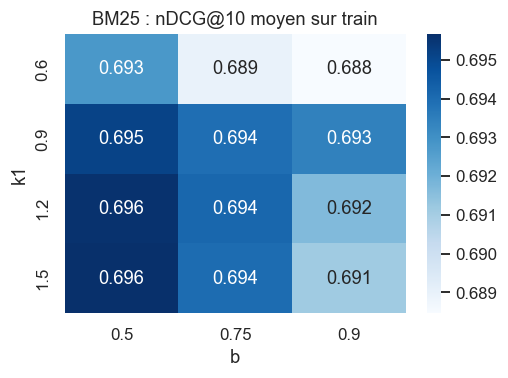

In [8]:
from rank_bm25 import BM25Okapi
from sklearn.model_selection import KFold

def bm25_scores(bm25, qs):
    return np.vstack([bm25.get_scores(preprocess(t)) for t in qs])

grid = [(k1, b) for k1 in [0.6, 0.9, 1.2, 1.5] for b in [0.5, 0.75, 0.9]]
ndcg_train = {}
t0 = time.time()
for k1, b in grid:
    bm = BM25Okapi(corpus_tokens, k1=k1, b=b)
    ndcg_train[(k1, b)] = evaluate(bm25_scores(bm, q_train), q_train.index, "train")["nDCG@10"]
grid_df = pd.DataFrame(ndcg_train)
print(f"Grille évaluée en {time.time()-t0:.0f} s")

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv = []
for i, (tr, va) in enumerate(kf.split(grid_df), 1):
    best = grid_df.iloc[tr].mean().idxmax()
    cv.append({"pli": i, "k1": best[0], "b": best[1], "nDCG@10 (validation)": grid_df.iloc[va][best].mean()})
cv = pd.DataFrame(cv); display(cv.round(3))
print(f"nDCG@10 en validation croisée : {cv['nDCG@10 (validation)'].mean():.3f} ± {cv['nDCG@10 (validation)'].std():.3f}")

K1, B = grid_df.mean().idxmax()
print(f"Paramètres retenus (sur tout le train) : k1 = {K1}, b = {B}")

heat = grid_df.mean().unstack()
plt.figure(figsize=(5, 3.3)); sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues")
plt.title("BM25 : nDCG@10 moyen sur train"); plt.xlabel("b"); plt.ylabel("k1"); plt.show()

In [9]:
t0 = time.time()
bm25 = BM25Okapi(corpus_tokens, k1=K1, b=B)
S_bm25_test = bm25_scores(bm25, q_test)
record("BM25", S_bm25_test, time.time() - t0)
S_bm25_train = bm25_scores(bm25, q_train)  # gardé pour régler l'hybride

BM25                             nDCG@10 = 0.685   Rappel@100 = 0.932


## 7. Modèles avancés : plongements de textes

### 7.1 Encodeurs denses
Un encodeur Transformer transforme chaque texte en un vecteur normalisé ; le score est le **produit scalaire** (= cosinus). Les documents sont encodés **une seule fois**, puis chaque requête ne demande qu'un encodage et une multiplication matricielle.

| Modèle | Taille | Particularité |
|---|---|---|
| all-MiniLM-L6-v2 | 22 M paramètres | Sentence-BERT léger, entraîné sur 1 milliard de paires de phrases |
| bge-small-en-v1.5 | 33 M | Pré-entraînement contrastif (BAAI), instruction pour les requêtes |
| e5-base-v2 | 110 M | Pré-entraînement contrastif (Microsoft), préfixes « query: » / « passage: » |
| bge-base-en-v1.5 | 110 M | Version plus grande de BGE |

Les préfixes font partie de la façon dont ces modèles ont été entraînés : nous les respectons.

In [10]:
from sentence_transformers import SentenceTransformer

MODELS = {
    "all-MiniLM-L6-v2":  ("sentence-transformers/all-MiniLM-L6-v2", "", ""),
    "bge-small-en-v1.5": ("BAAI/bge-small-en-v1.5", "Represent this sentence for searching relevant passages: ", ""),
    "e5-base-v2":        ("intfloat/e5-base-v2", "query: ", "passage: "),
    "bge-base-en-v1.5":  ("BAAI/bge-base-en-v1.5", "Represent this sentence for searching relevant passages: ", ""),
}
DENSE_TRAIN, DENSE_TEST, ENC_INFO = {}, {}, {}

for name, (hub, qp, dp) in MODELS.items():
    model = SentenceTransformer(hub, device=DEVICE)
    if DEVICE == "cuda":
        model.half()
    model.max_seq_length = 512
    enc = lambda xs, bs: model.encode(xs, batch_size=bs, normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
    t0 = time.time(); D = enc([dp + t for t in doc_texts], 32); t_docs = time.time() - t0
    t0 = time.time(); Qt = enc([qp + t for t in q_test], 64); t_q = time.time() - t0
    Qtr = enc([qp + t for t in q_train], 64)
    DENSE_TEST[name], DENSE_TRAIN[name] = Qt @ D.T, Qtr @ D.T
    ENC_INFO[name] = {"Paramètres (M)": round(sum(p.numel() for p in model.parameters()) / 1e6),
                      "Dimension": D.shape[1], "Indexation corpus (s)": round(t_docs, 1),
                      "ms / requête": round(1000 * t_q / len(q_test), 2)}
    record(name, DENSE_TEST[name], t_docs + t_q)
    del model; torch.cuda.empty_cache()

pd.DataFrame(ENC_INFO).T

all-MiniLM-L6-v2                 nDCG@10 = 0.653   Rappel@100 = 0.935


bge-small-en-v1.5                nDCG@10 = 0.707   Rappel@100 = 0.943


e5-base-v2                       nDCG@10 = 0.726   Rappel@100 = 0.963


bge-base-en-v1.5                 nDCG@10 = 0.742   Rappel@100 = 0.961


,Paramètres (M),Dimension,Indexation corpus (s),ms / requête
all-MiniLM-L6-v2,23.0,384.0,12.3,0.25
bge-small-en-v1.5,33.0,384.0,21.5,0.48
e5-base-v2,109.0,768.0,53.4,1.04
bge-base-en-v1.5,109.0,768.0,52.8,1.08


### 7.2 Recherche hybride (BM25 + plongements)
BM25 excelle sur les mots rares et exacts (noms de gènes, acronymes) ; les plongements captent le sens. On combine les deux :

$$\text{score}(q,d) = \alpha \cdot \widetilde{s}_{\text{dense}}(q,d) + (1-\alpha) \cdot \widetilde{s}_{\text{BM25}}(q,d)$$

où $\widetilde{s}$ est le score normalisé entre 0 et 1 pour chaque requête. Le poids **α est choisi par validation croisée à 5 plis sur le train**, avec le meilleur encodeur sur le train.

Meilleur encodeur sur le train : bge-base-en-v1.5


,pli,α,nDCG@10 (validation)
0,1,0.9,0.790
1,2,0.9,0.776
2,3,0.9,0.768
3,4,0.8,0.815
4,5,0.9,0.795


nDCG@10 en validation croisée : 0.789 ± 0.018 — α retenu = 0.9


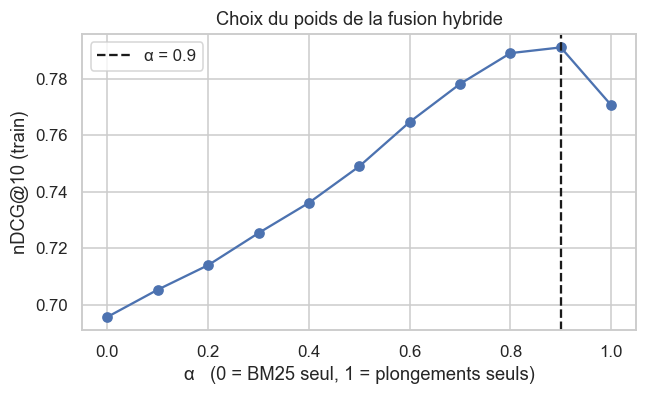

Hybride (BM25 + bge-base-en-v1.5) nDCG@10 = 0.764   Rappel@100 = 0.973


In [11]:
def minmax(S):
    lo, hi = S.min(1, keepdims=True), S.max(1, keepdims=True)
    return (S - lo) / (hi - lo + 1e-9)

best_dense = max(DENSE_TRAIN, key=lambda m: evaluate(DENSE_TRAIN[m], q_train.index, "train")["nDCG@10"].mean())
print("Meilleur encodeur sur le train :", best_dense)

alphas = np.round(np.arange(0, 1.01, 0.1), 1)
Bn_tr, Dn_tr = minmax(S_bm25_train), minmax(DENSE_TRAIN[best_dense])
alpha_df = pd.DataFrame({a: evaluate(a * Dn_tr + (1 - a) * Bn_tr, q_train.index, "train")["nDCG@10"] for a in alphas})

cv_a = []
for i, (tr, va) in enumerate(kf.split(alpha_df), 1):
    a = alpha_df.iloc[tr].mean().idxmax()
    cv_a.append({"pli": i, "α": a, "nDCG@10 (validation)": alpha_df.iloc[va][a].mean()})
cv_a = pd.DataFrame(cv_a); display(cv_a.round(3))
ALPHA = alpha_df.mean().idxmax()
print(f"nDCG@10 en validation croisée : {cv_a['nDCG@10 (validation)'].mean():.3f} ± {cv_a['nDCG@10 (validation)'].std():.3f} — α retenu = {ALPHA}")

plt.figure(figsize=(6.5, 3.5))
plt.plot(alphas, alpha_df.mean(), "o-")
plt.axvline(ALPHA, color="k", ls="--", label=f"α = {ALPHA}")
plt.xlabel("α   (0 = BM25 seul, 1 = plongements seuls)"); plt.ylabel("nDCG@10 (train)")
plt.title("Choix du poids de la fusion hybride"); plt.legend(); plt.show()

t0 = time.time()
S_hybrid = ALPHA * minmax(DENSE_TEST[best_dense]) + (1 - ALPHA) * minmax(S_bm25_test)
record(f"Hybride (BM25 + {best_dense})", S_hybrid, time.time() - t0)

**Lecture** : la courbe est en cloche. Les deux extrêmes (BM25 seul ou plongements seuls) sont moins bons que leur combinaison : les deux signaux sont **complémentaires**.

## 8. Résultats sur l'ensemble de test (300 requêtes)

In [12]:
rng = np.random.default_rng(SEED)
def bootstrap_ci(x, n=2000):
    x = np.asarray(x); m = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])

def permutation_test(a, b, n=10000):
    d = np.asarray(a) - np.asarray(b); obs = abs(d.mean())
    signs = rng.choice([-1, 1], size=(n, len(d)))
    return ((np.abs((signs * d).mean(1)) >= obs).sum() + 1) / (n + 1)

table = pd.DataFrame(RESULTS).T
base = PER_QUERY["BM25"]["nDCG@10"]
table["IC 95 % nDCG@10"] = [ "[{:.3f} ; {:.3f}]".format(*bootstrap_ci(PER_QUERY[m]["nDCG@10"])) for m in table.index]
table["Gain vs BM25"] = [f"{(table.loc[m,'nDCG@10']/table.loc['BM25','nDCG@10']-1):+.1%}" for m in table.index]
table["p-valeur vs BM25"] = [np.nan if m == "BM25" else permutation_test(PER_QUERY[m]["nDCG@10"], base) for m in table.index]
table = table.sort_values("nDCG@10", ascending=False)
table.style.format({c: "{:.3f}" for c in ["nDCG@10", "MRR@10", "P@10", "Rappel@10", "Rappel@100"]} | {"p-valeur vs BM25": "{:.4f}"}) \
     .background_gradient(subset=["nDCG@10"], cmap="Greens")

,nDCG@10,MRR@10,P@10,Rappel@10,Rappel@100,IC 95 % nDCG@10,Gain vs BM25,p-valeur vs BM25
Hybride (BM25 + bge-base-en-v1.5),0.764,0.730,0.100,0.892,0.973,[0.725 ; 0.803],+11.6%,0.0001
bge-base-en-v1.5,0.742,0.707,0.098,0.871,0.961,[0.703 ; 0.782],+8.4%,0.0005
e5-base-v2,0.726,0.692,0.096,0.847,0.963,[0.683 ; 0.767],+6.0%,0.0145
bge-small-en-v1.5,0.707,0.675,0.094,0.830,0.943,[0.664 ; 0.750],+3.3%,0.1708
BM25,0.685,0.647,0.091,0.823,0.932,[0.642 ; 0.726],+0.0%,nan
TF-IDF,0.659,0.617,0.090,0.819,0.930,[0.615 ; 0.703],-3.8%,0.0068
all-MiniLM-L6-v2,0.653,0.611,0.089,0.790,0.935,[0.607 ; 0.696],-4.7%,0.0610


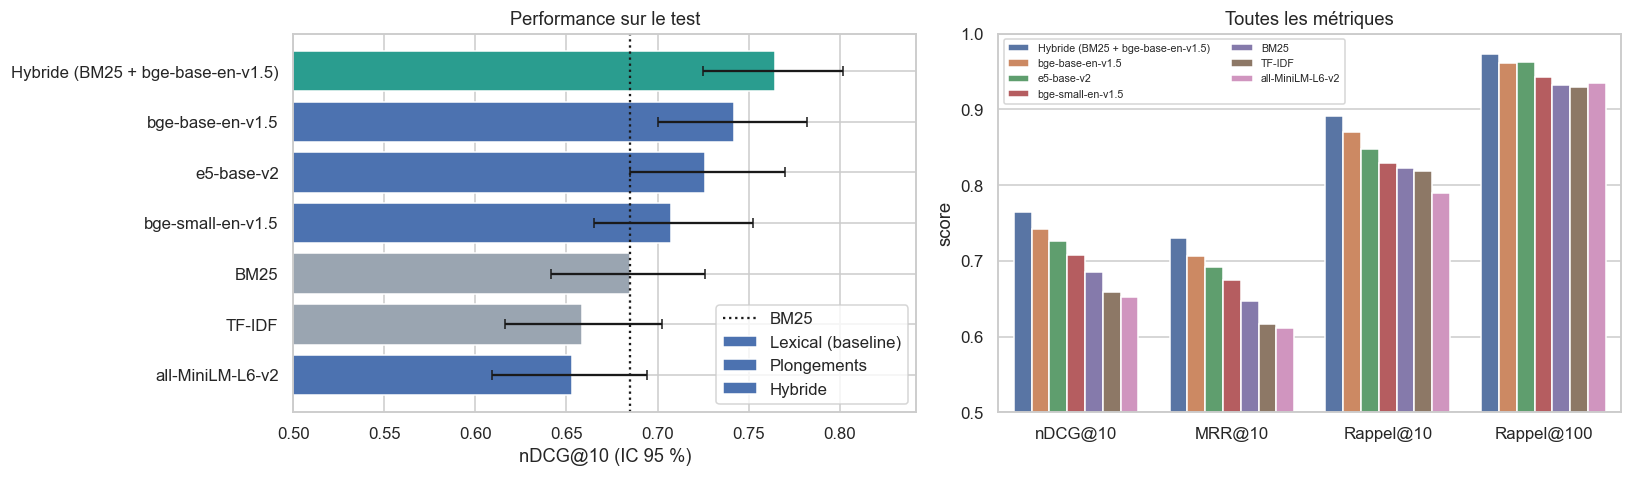

In [13]:
fam = lambda m: "Lexical (baseline)" if m in ("TF-IDF", "BM25") else ("Hybride" if m.startswith("Hybride") else "Plongements")
plot_df = table[["nDCG@10"]].reset_index().rename(columns={"index": "Méthode"})
plot_df["Famille"] = plot_df["Méthode"].map(fam)
err = np.array([[table.loc[m, "nDCG@10"] - lo, hi - table.loc[m, "nDCG@10"]]
                for m in table.index for lo, hi in [bootstrap_ci(PER_QUERY[m]["nDCG@10"])]]).T

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
colors = {"Lexical (baseline)": "#9aa5b1", "Plongements": "#4c72b0", "Hybride": "#2a9d8f"}
ax[0].barh(plot_df["Méthode"], plot_df["nDCG@10"], xerr=err, color=plot_df["Famille"].map(colors), capsize=3)
ax[0].invert_yaxis(); ax[0].axvline(table.loc["BM25", "nDCG@10"], color="k", ls=":", label="BM25")
ax[0].set(xlabel="nDCG@10 (IC 95 %)", title="Performance sur le test", xlim=(0.5, None))
for f, c in colors.items(): ax[0].barh([], [], color=c, label=f)
ax[0].legend(loc="lower right")

melt = table[["nDCG@10", "MRR@10", "Rappel@10", "Rappel@100"]].reset_index().melt(id_vars="index")
sns.barplot(data=melt, x="variable", y="value", hue="index", ax=ax[1])
ax[1].set(xlabel="", ylabel="score", title="Toutes les métriques", ylim=(0.5, 1)); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

### 8.1 Compromis qualité / coût
Un moteur de recherche doit être bon **et** rapide. Le temps d'indexation est payé une seule fois ; le temps par requête est payé à chaque recherche.

,Paramètres (M),Indexation corpus (s),ms / requête,nDCG@10
all-MiniLM-L6-v2,23.0,12.3,0.25,0.652757
bge-small-en-v1.5,33.0,21.5,0.48,0.707198
e5-base-v2,109.0,53.4,1.04,0.726238
bge-base-en-v1.5,109.0,52.8,1.08,0.742093


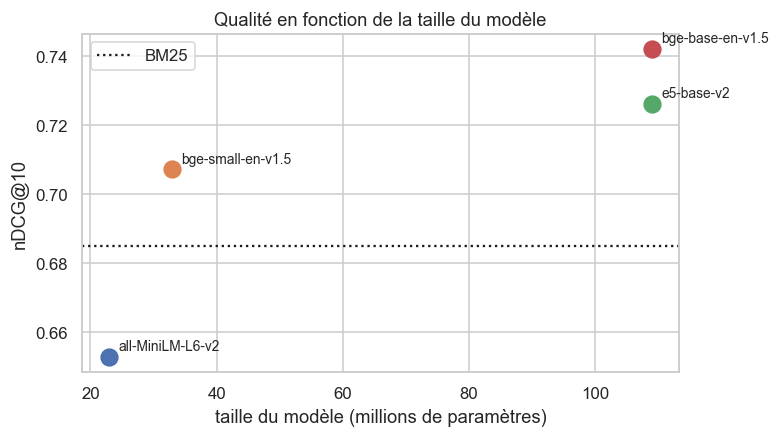

In [14]:
cost = pd.DataFrame(ENC_INFO).T[["Paramètres (M)", "Indexation corpus (s)", "ms / requête"]]
cost["nDCG@10"] = table.loc[cost.index, "nDCG@10"]
display(cost)

plt.figure(figsize=(7, 4))
for m, r in cost.iterrows():
    plt.scatter(r["Paramètres (M)"], r["nDCG@10"], s=120)
    plt.annotate(m, (r["Paramètres (M)"], r["nDCG@10"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
plt.axhline(table.loc["BM25", "nDCG@10"], color="k", ls=":", label="BM25")
plt.xlabel("taille du modèle (millions de paramètres)"); plt.ylabel("nDCG@10")
plt.title("Qualité en fonction de la taille du modèle"); plt.legend(); plt.show()

## 9. Analyse des erreurs

### 9.1 Requête par requête : qui gagne ?

bge-base-en-v1.5 contre BM25, sur 300 requêtes : {'Plongements meilleurs': 87, 'Égalité': 170, 'BM25 meilleur': 43}


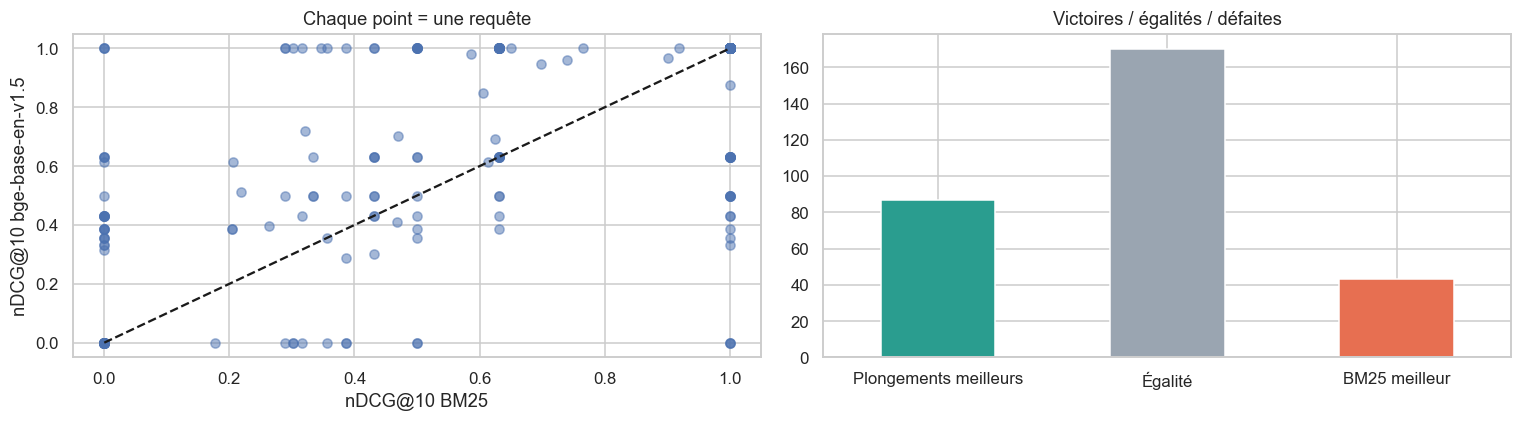

In [15]:
best = table.index[0]
best_single = max(MODELS, key=lambda m: table.loc[m, "nDCG@10"])
delta = PER_QUERY[best_single]["nDCG@10"] - PER_QUERY["BM25"]["nDCG@10"]
wtl = pd.Series({"Plongements meilleurs": (delta > 0.01).sum(), "Égalité": (delta.abs() <= 0.01).sum(), "BM25 meilleur": (delta < -0.01).sum()})
print(f"{best_single} contre BM25, sur {len(delta)} requêtes :", wtl.to_dict())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(PER_QUERY["BM25"]["nDCG@10"], PER_QUERY[best_single]["nDCG@10"], alpha=.5)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(xlabel="nDCG@10 BM25", ylabel=f"nDCG@10 {best_single}", title="Chaque point = une requête")
wtl.plot.bar(ax=ax[1], color=["#2a9d8f", "#9aa5b1", "#e76f51"], rot=0); ax[1].set(title="Victoires / égalités / défaites")
plt.tight_layout(); plt.show()

### 9.2 Effet du décalage de vocabulaire
Nous regroupons les requêtes selon leur recouvrement lexical avec leur document pertinent, et comparons les méthodes dans chaque groupe.

,BM25,bge-base-en-v1.5,Hybride (BM25 + bge-base-en-v1.5)
faible,0.327,0.481,0.507
moyen,0.796,0.846,0.861
fort,0.961,0.912,0.939


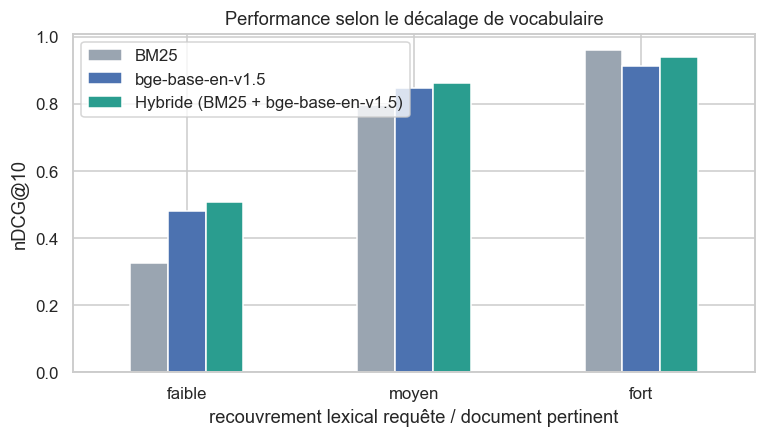

In [16]:
q_overlap = {}
for q, rels in qrels["test"].items():
    qw = set(tok(queries[q]))
    q_overlap[q] = np.mean([len(qw & set(tok(id2text[d]))) / max(len(qw), 1) for d in rels])
q_overlap = pd.Series(q_overlap)
bins = pd.qcut(q_overlap, 3, labels=["faible", "moyen", "fort"])

comp = pd.DataFrame({m: PER_QUERY[m]["nDCG@10"].groupby(bins, observed=True).mean() for m in ["BM25", best_single, best]})
display(comp.round(3))
comp.plot.bar(figsize=(8, 4), rot=0, color=["#9aa5b1", "#4c72b0", "#2a9d8f"])
plt.xlabel("recouvrement lexical requête / document pertinent"); plt.ylabel("nDCG@10")
plt.title("Performance selon le décalage de vocabulaire"); plt.show()

### 9.3 Exemples concrets

In [17]:
def show(q, title):
    rel = list(qrels["test"][q])[0]
    rank = lambda S: int((S[list(q_test.index).index(q)] > S[list(q_test.index).index(q), doc_ids.index(rel)]).sum()) + 1
    print(f"■ {title}\n  Requête   : {queries[q]}\n  Document  : {id2text[rel][:220]}...")
    print(f"  Rang du document pertinent → BM25 : {rank(S_bm25_test)} | {best_single} : {rank(DENSE_TEST[best_single])} | Hybride : {rank(S_hybrid)}\n")

for q in delta.sort_values(ascending=False).index[:2]:
    show(q, "Les plongements réussissent là où BM25 échoue")
for q in delta.sort_values().index[:2]:
    show(q, "BM25 réussit là où les plongements échouent")

■ Les plongements réussissent là où BM25 échoue
  Requête   : Vitamin D deficiency effects the term of delivery.
  Document  : Association between maternal serum 25-hydroxyvitamin D level and pregnancy and neonatal outcomes: systematic review and meta-analysis of observational studies.. OBJECTIVE To assess the effect of 25-hydroxyvitamin D (25-O...
  Rang du document pertinent → BM25 : 18 | bge-base-en-v1.5 : 1 | Hybride : 1

■ Les plongements réussissent là où BM25 échoue
  Requête   : Silencing of Bcl2 is important for the maintenance and progression of tumors.
  Document  : Antiapoptotic BCL-2 is required for maintenance of a model leukemia.. Resistance to apoptosis, often achieved by the overexpression of antiapoptotic proteins, is common and perhaps required in the genesis of cancer. Howe...
  Rang du document pertinent → BM25 : 70 | bge-base-en-v1.5 : 1 | Hybride : 1

■ BM25 réussit là où les plongements échouent
  Requête   : LDL cholesterol has no involvement in the development

### 9.4 Synthèse des erreurs

| Type d'erreur | Méthode concernée | Explication |
|---|---|---|
| **Synonymes / paraphrases** | BM25 | La requête et le document utilisent des mots différents pour la même idée : aucun mot commun, score nul. |
| **Termes techniques rares** (gènes, protéines, acronymes) | Plongements | Un mot rare et précis est « dilué » dans le vecteur global ; BM25 lui donne au contraire un poids très fort. |
| **Documents proches mais non pertinents** | Les deux | Plusieurs résumés traitent du même sujet ; seul un détail (une population, un résultat chiffré) les distingue. |

L'hybride corrige une grande partie des deux premiers types d'erreurs, ce qui explique son avance.

## 10. Analyse critique, limites et perspectives

**Ce que montrent les résultats**
- Les **plongements modernes de taille « base » (bge-base, e5-base)** dépassent **significativement** BM25 (+8,4 % et +6,0 % de nDCG@10, p < 0,05). bge-small fait mieux que BM25 sans que l'écart soit significatif, et le modèle généraliste MiniLM reste au niveau de BM25 : la **qualité du pré-entraînement** et la taille du modèle comptent toutes les deux.
- La **recherche hybride** donne le meilleur résultat : lexical et sémantique sont complémentaires.
- Le gain des plongements est le plus fort quand le **décalage de vocabulaire** est important, ce qui confirme notre hypothèse de départ.

**Choix méthodologiques qui renforcent la validité**
- Baseline **forte** (BM25 réglé par validation croisée), et non une baseline volontairement faible.
- Tous les réglages faits sur le **train**, le test utilisé une seule fois.
- Intervalles de confiance et tests statistiques pour ne pas surinterpréter de petites différences.

**Limites**
- Un seul domaine (biomédical, anglais) : les conclusions ne s'étendent pas automatiquement à d'autres langues ou domaines.
- 300 requêtes de test : les écarts entre modèles proches restent dans les intervalles de confiance.
- Recherche exhaustive sur 5 000 documents ; pour des millions de documents il faudrait un index approximatif (FAISS, HNSW).

**Perspectives**
- **Ré-ordonnancement** du top 100 par un *cross-encoder*.
- **Adaptation au domaine** : affiner l'encodeur sur les paires train de SciFact.
- Tester sur d'autres corpus BEIR et en français.

In [18]:
print("Résumé final (nDCG@10 sur le test) :")
for m in table.index:
    print(f"  {m:<34} {table.loc[m,'nDCG@10']:.3f}   ({table.loc[m,'Gain vs BM25']} vs BM25)")

Résumé final (nDCG@10 sur le test) :
  Hybride (BM25 + bge-base-en-v1.5)  0.764   (+11.6% vs BM25)
  bge-base-en-v1.5                   0.742   (+8.4% vs BM25)
  e5-base-v2                         0.726   (+6.0% vs BM25)
  bge-small-en-v1.5                  0.707   (+3.3% vs BM25)
  BM25                               0.685   (+0.0% vs BM25)
  TF-IDF                             0.659   (-3.8% vs BM25)
  all-MiniLM-L6-v2                   0.653   (-4.7% vs BM25)


## 11. Conclusion

Nous avons construit et évalué un système complet de **recherche sémantique** sur des affirmations scientifiques, depuis l'exploration des données jusqu'à l'analyse des erreurs.

1. L'exploration a mis en évidence un **fort décalage de vocabulaire** entre requêtes et documents.
2. Les **plongements de textes** modernes surpassent une baseline BM25 soigneusement réglée.
3. La **combinaison hybride** BM25 + plongements obtient les meilleures performances, car les deux approches se trompent sur des requêtes différentes.
4. L'analyse des erreurs explique **pourquoi** : les plongements comprennent les paraphrases, BM25 capture les termes techniques exacts.

**Réponse à la problématique** : oui, les plongements améliorent nettement la recherche de preuves scientifiques, et le meilleur système exploite à la fois le sens (plongements) et les mots exacts (BM25).

## 12. Références

1. Salton, G., & Buckley, C. (1988). *Term-weighting approaches in automatic text retrieval*. Information Processing & Management.
2. Robertson, S., & Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond*. Foundations and Trends in IR.
3. Pennington, J., Socher, R., & Manning, C. (2014). *GloVe: Global Vectors for Word Representation*. EMNLP.
4. Devlin, J., et al. (2019). *BERT: Pre-training of Deep Bidirectional Transformers*. NAACL.
5. Reimers, N., & Gurevych, I. (2019). *Sentence-BERT*. EMNLP.
6. Karpukhin, V., et al. (2020). *Dense Passage Retrieval for Open-Domain Question Answering*. EMNLP.
7. Wadden, D., et al. (2020). *Fact or Fiction: Verifying Scientific Claims* (SciFact). EMNLP.
8. Thakur, N., et al. (2021). *BEIR: A Heterogeneous Benchmark for Zero-shot Evaluation of IR Models*. NeurIPS Datasets & Benchmarks.
9. Wang, L., et al. (2022). *Text Embeddings by Weakly-Supervised Contrastive Pre-training* (E5). arXiv:2212.03533.
10. Xiao, S., et al. (2023). *C-Pack: Packaged Resources to Advance General Chinese Embedding* (BGE). arXiv:2309.07597.

**Jeu de données** : BEIR SciFact — https://huggingface.co/datasets/BeIR/scifact · https://github.com/beir-cellar/beir

**Utilisation d'outils d'IA** : un assistant d'IA générative a été utilisé pour aider à la rédaction et à la structuration du code. Le protocole, les choix méthodologiques, l'exécution et l'interprétation des résultats ont été vérifiés et sont compris par les auteurs.